# SFigure2 panels -- corrected gene set

The same panels as `SFigure2/SFigure2.ipynb`, restricted to the 16,073
higher-confidence genes from `analysis/Fig1Numbers.ipynb`: Torino reached
K=10 in at least 100 samples, the gene carries a corrected isoform
annotation, and it does not overlap another gene.

This is a **filter, not a recomputation**. The modules are the same ones
the uncorrected notebook uses; setting `R.GENE_SUBSET` makes every loader
cut its table down to those genes after reading it. Nothing is rebuilt and
nothing is written.

**Memory.** Each panel drops its inputs when it is done, so the notebook
does not accumulate; most panels peak near 1.5 GB. The PCA panels are
commented out -- they need ~6-8 GB and will kill a kernel on a login node.

**Status.** All 29 panels are written and wired up here. Two caveats,
both real:

- `UTRs_cumulative` is **not** written. Its inputs come from counting long
  reads per polyA site across nine ONT BAMs (`UTR3.ipynb` cell 278), and
  nothing on disk caches that intermediate.
- The four expression-decile panels (`PCA_rank1`, `heatmap_rank1`,
  `PCA_rank20`, `heatmap_rank20`) are written but **do not reproduce their
  published figures** (corr 0.74 and 0.55). `PCA_rank1` and `PCA_rank20`
  score 0.735 and 0.734, i.e. they draw nearly the same figure, so the
  decile filter is not separating the two groups. Treat them as unverified.

20 of the remaining panels have been checked against the published PNG at
its own dpi and reproduce it pixel for pixel (`SFigure2_verify.verify()`).


In [1]:
import sys

ROOT = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks'
sys.path.insert(0, '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure2')

from IPython.display import Markdown

import SFigure2_intron_retention as R      # intron retention panels + tables
import SFigure2_coverage as C              # CGB8 coverage panels
import SFigure2_cassette as K              # cassette-exon panels + table
import SFigure2_brain_ssmd as B            # VastDB brain cassette panel
import SFigure2_appris as A                # annotation-recovery panels
import SFigure2_utr3 as U                  # polyA panels + table
import SFigure2_upset as UP                # standalone full upset

# the one line that makes this the corrected notebook
R.GENE_SUBSET = R.load_select_genes()
print(f'restricted to {len(R.GENE_SUBSET):,} genes')



restricted to 16,073 genes


In [ ]:
# ---------------------------------------------------------------------------
# Saving. Every panel cell below is wrapped in save(...), so running the
# notebook writes the figures -- there is no separate step and nothing to
# remember. Each panel lands in panels/ next to this notebook, as PNG and PDF:
#
#     /project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure2_corrected/panels
#
# The save is done here, in the notebook, rather than inside the modules, so
# what writes your figures is visible in the cell that draws them.
# ---------------------------------------------------------------------------
import os
from matplotlib import pyplot as plt

# Absolute: importing the modules changes the working directory to analysis/,
# which is what the source notebooks' relative paths are written against.
PANEL_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure2_corrected/panels'
os.makedirs(PANEL_DIR, exist_ok=True)
SAVE_DPI = 400
SAVE_FORMATS = ('png', 'pdf')

R.SAVE_DIR = None          # the modules do not save; this notebook does


def save(result, name):
    """Write the panel just drawn to panels/<name>.png and .pdf."""
    fig = getattr(result, 'figure', result)
    if not hasattr(fig, 'savefig'):
        fig = plt.gcf()            # panels that return None or a seaborn grid
    out = []
    for ext in SAVE_FORMATS:
        path = os.path.join(PANEL_DIR, f'{name}.{ext}')
        fig.savefig(path, dpi=SAVE_DPI, bbox_inches='tight')
        out.append(os.path.basename(path))
    print(f'[saved] {name}  ->  ' + ', '.join(out))
    return fig


print(f'figures will be saved to {PANEL_DIR}')


In [2]:
# Drop whatever is loaded, at any point, if memory gets tight.
R.free()


## Intron retention

From `analysis/Retained_Introns_figure.ipynb`, over the corrected gene set.
These will not match the published figures -- that is the point of the
correction -- so there is nothing to verify them against.

### intron_metaplot_quintiles
Source: `analysis/Retained_Introns_figure.ipynb cell 68`

(57682, 149)


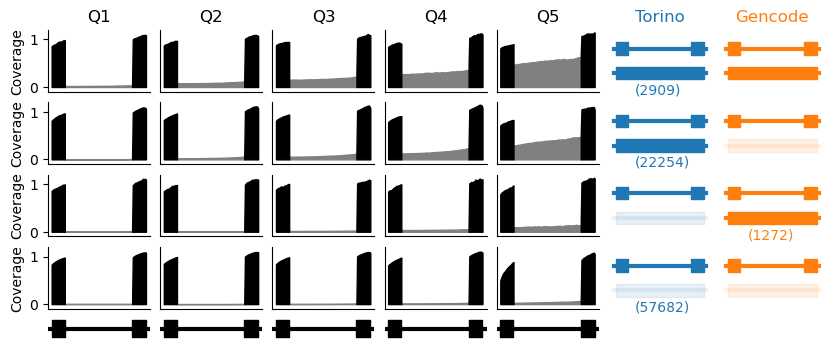

In [3]:
save(R.panel_intron_metaplot_quintiles(), 'intron_metaplot_quintiles')

### intron_metaplot_quintiles_vastdb
Source: `analysis/Retained_Introns_figure.ipynb cell 70`

(3165, 149)


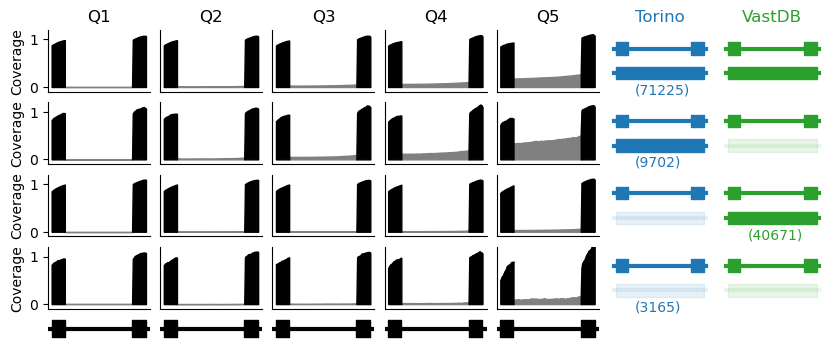

In [4]:
save(R.panel_intron_metaplot_quintiles_vastdb(), 'intron_metaplot_quintiles_vastdb')

### intron_metaplot_Liver
Source: `analysis/Retained_Introns_figure.ipynb cell 79`

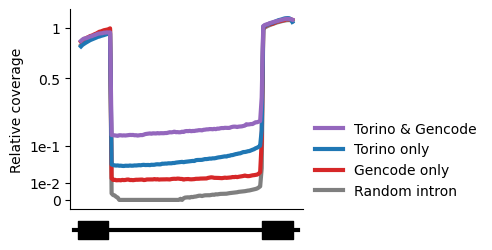

In [5]:
save(R.panel_intron_metaplot_Liver(), 'intron_metaplot_Liver')

### intron_cdf_Liver
Source: `analysis/Retained_Introns_figure.ipynb cell 144`

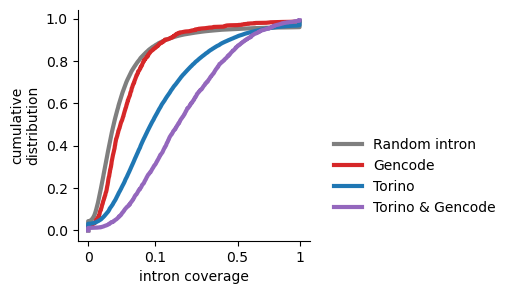

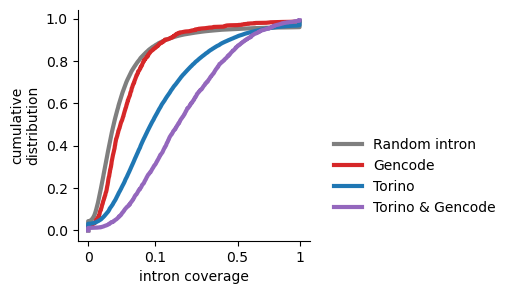

In [6]:
save(R.panel_intron_cdf_Liver(), 'intron_cdf_Liver')

### intron_barplot
Source: `analysis/Retained_Introns_figure.ipynb` cell 137

The notebook hardcodes the five counts; `R.intron_counts()` recomputes
them over the gene subset. Four are table lengths, and the VastDB bar is
the notebook's own `In[102]` definition -- VastDB introns in genes Torino
annotates, matched through Ensembl ids. With no subset it reproduces the
published `[174635, 158506, 115176, 25305, 9131]` exactly.

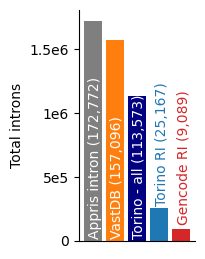

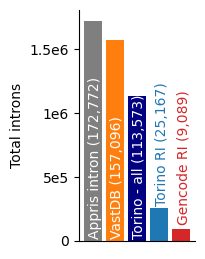

In [7]:
save(R.panel_intron_barplot(), 'intron_barplot')

## Retained-intron numbers

Every count below is recomputed here, and each row names the cell of
`analysis/Retained_Introns_figure.ipynb` that produced it. Run the cell to
render the table.

In [8]:
Markdown(R.intron_retention_table())


**Retained introns**

| | all genes | corrected gene set | source |
|---|---:|---:|---|
| Retained introns observed by Torino | 115,176 | 113,573 | `In[82]` |
| &nbsp;&nbsp;across transcripts | 53,762 | 52,974 | `In[90]` |
| &nbsp;&nbsp;across genes | 14,505 (86.8%) | 14,084 (87.6%) | `In[84]` |
| &nbsp;&nbsp;genes tested | 16,710 | 16,073 | `annot` |
| Classified as true IR | 25,305 (22.0%) | 25,167 (22.2%) | `In[95]` |
| &nbsp;&nbsp;across genes | 11,601 | 11,491 | `In[86]` |
| &nbsp;&nbsp;not annotated by GENCODE | 22,386 (88.5%) | 22,254 (88.4%) | `In[53]` |
| Splicing-efficiency factors | 89,758 (77.9%) | 88,295 (77.7%) | `derived` |
| &nbsp;&nbsp;matched by GENCODE | 4,931 (5.5%) | 4,898 (5.5%) | `derived` |
| &nbsp;&nbsp;not matched by GENCODE | 84,822 (94.5%) | 83,392 (94.4%) | `derived` |
| GENCODE retained introns | 9,131 | 9,089 | `In[99]` |
| &nbsp;&nbsp;observed by Torino | 7,854 (86.0%) | 7,815 (86.0%) | `In[48]` |
| &nbsp;&nbsp;&nbsp;&nbsp;matching a true IR event | 2,915 (31.9%) | 2,909 (32.0%) | `In[49]` |
| &nbsp;&nbsp;&nbsp;&nbsp;a splicing-efficiency factor | 4,941 (54.1%) | 4,908 (54.0%) | `derived` |
| &nbsp;&nbsp;missing from Torino | 1,275 (14.0%) | 1,272 (14.0%) | `In[52]` |

## Cassette-exon numbers

Recomputed here for both gene sets; each row names the cell of
`analysis/CassetteExonsDeNovo.ipynb` it comes from. "exon only" asks whether
the cassette exon itself is annotated; "flanking exons also matching"
requires the flanks to agree too, which is why it is the smaller number.

Takes a couple of minutes -- it reads the Gencode exon annotation and the
VastDB event table, once per gene set.

In [9]:
Markdown(K.cassette_table())


**Cassette exons**

| | all genes | corrected gene set | source |
|---|---:|---:|---|
| Cassette exons called by Torino | 21,069 | 21,017 | `In[98]` |
| &nbsp;&nbsp;across genes | 7,297 | 7,263 | `In[26]` |
| Matching Gencode or VastDB (exon only) | 11,058 (52.5%) | 11,014 (52.4%) | `In[43]` |
| &nbsp;&nbsp;flanking exons also matching | 9,501 (45.1%) | 9,467 (45.0%) | `In[41]` |
| &nbsp;&nbsp;&nbsp;&nbsp;matching Gencode | 5,340 (25.3%) | 5,332 (25.4%) | `In[46]` |
| &nbsp;&nbsp;&nbsp;&nbsp;matching VastDB | 8,250 (39.2%) | 8,217 (39.1%) | `In[45]` |
| Overlapping an annotated exon | 15,978 (75.8%) | 15,927 (75.8%) | `derived` |
| &nbsp;&nbsp;constitutive or partial match only | 4,920 (23.4%) | 4,913 (23.4%) | `In[191]` |
| No match to Gencode or VastDB structures | 5,091 (24.2%) | 5,090 (24.2%) | `In[55]` |

## Cassette exons

From `analysis/CassetteExonsDeNovo.ipynb`. The cassette exons are split
five ways -- annotated by both Gencode and VastDB, by one only, unannotated
but overlapping an annotated exon, and overlapping nothing -- and each
group gets a coverage metaplot across quintiles.

The Torino and Gencode cassette tables are read back from the bed files the
notebook wrote, not rebuilt by the per-gene loop that produced them.

### cassette_exons_brain_cortex
Source: `analysis/CassetteExonsDeNovo.ipynb cell 76`

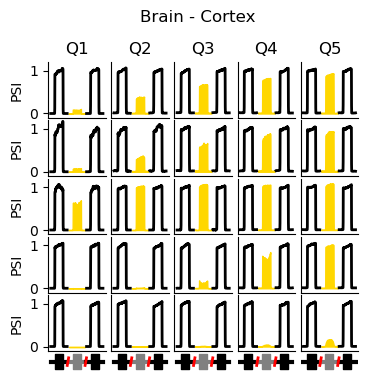

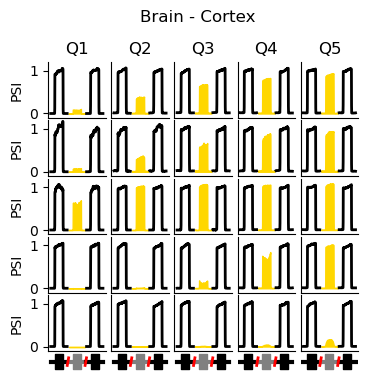

In [10]:
save(K.panel_cassette_exons_brain_cortex(), 'cassette_exons_brain_cortex')

### cassette_exons_heart_atrial_appendage
Source: `analysis/CassetteExonsDeNovo.ipynb cell 77`

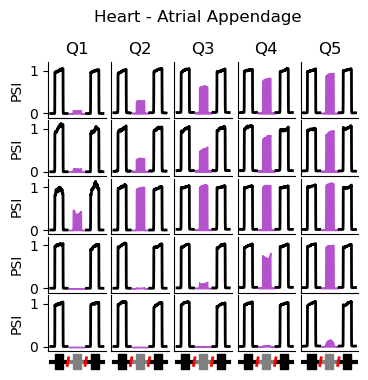

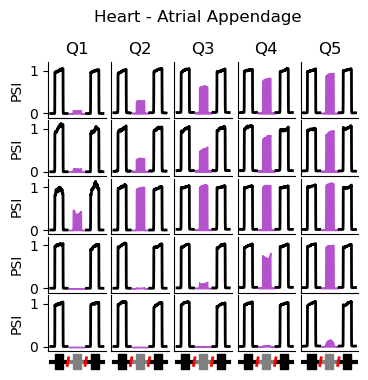

In [11]:
save(K.panel_cassette_exons_heart_atrial_appendage(), 'cassette_exons_heart_atrial_appendage')

### cassette_exons_liver
Source: `analysis/CassetteExonsDeNovo.ipynb cell 78`

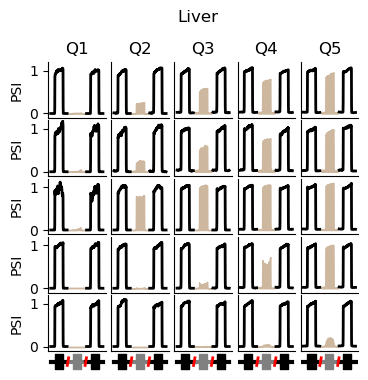

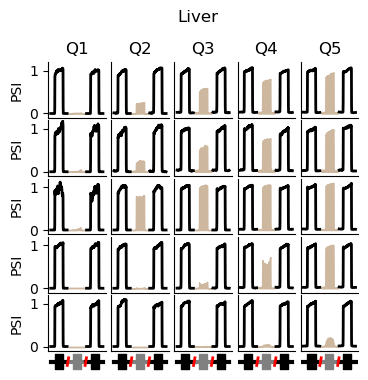

In [12]:
save(K.panel_cassette_exons_liver(), 'cassette_exons_liver')

### Exons per metaplot row

The five rows of the three cassette-exon metaplots above are annotation
groups; the five columns within a row are expression quintiles of that
row's exons. Source: `CassetteExonsDeNovo.ipynb` cell 76 (In[67]).

In [ ]:
Markdown(K.cassette_row_table())


### PCA_all / PCA_introns
Source: `analysis/Retained_Introns_figure.ipynb` cells 174, 175

Need ~6-8 GB; uncomment under `sinteractive --mem=16G`.

In [13]:
# save(R.panel_PCA_all(), 'PCA_all')
# save(R.panel_PCA_introns(), 'PCA_introns')


## CGB8 coverage

From `analysis/CoveragePlots.ipynb`. These are single-gene panels, so the
gene subset only matters in whether CGB8 survives it -- the cell below
says. If it does, these are identical to the uncorrected versions.

In [14]:
print('CGB8 in the corrected gene set:', 'CGB8' in set(R.GENE_SUBSET))


CGB8 in the corrected gene set: True


### torino_missing_junctions_CGB8_factors
Source: `analysis/CoveragePlots.ipynb cell 5`

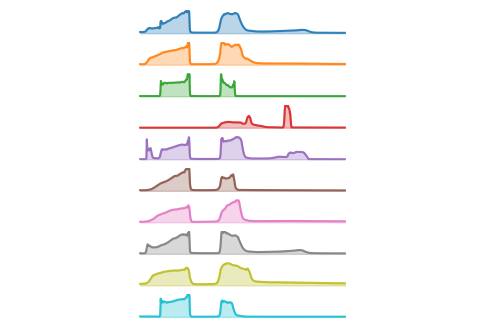

In [15]:
save(C.panel_torino_missing_junctions_CGB8_factors(), 'torino_missing_junctions_CGB8_factors')

### torino_missing_junctions_CGB8_iso
Source: `analysis/CoveragePlots.ipynb cell 6`

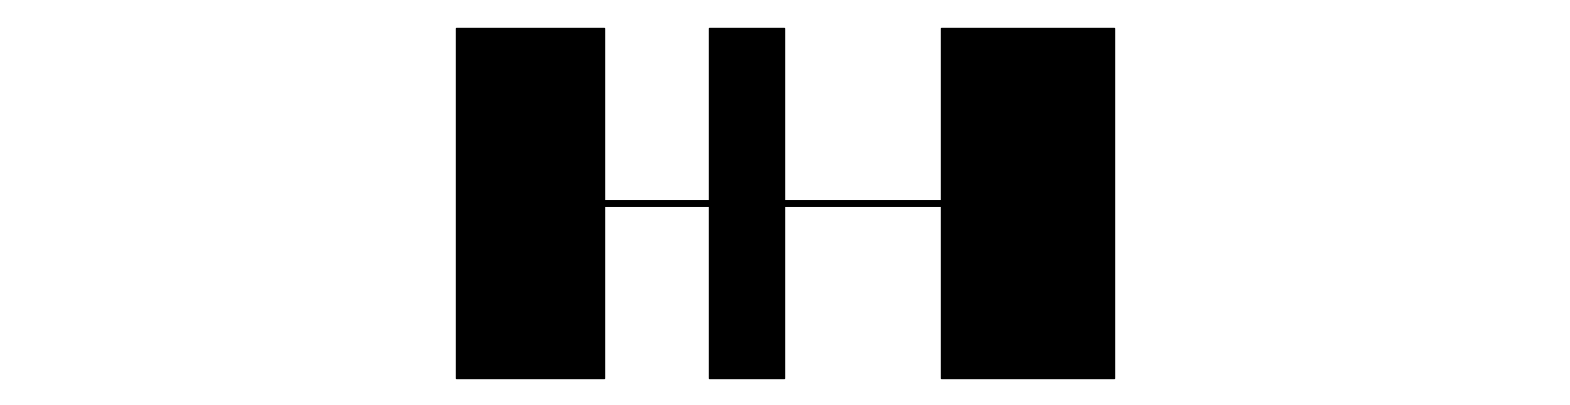

In [16]:
save(C.panel_torino_missing_junctions_CGB8_iso(), 'torino_missing_junctions_CGB8_iso')

### torino_missing_junctions_CGB8_torino_iso
Source: `analysis/CoveragePlots.ipynb cell 7`

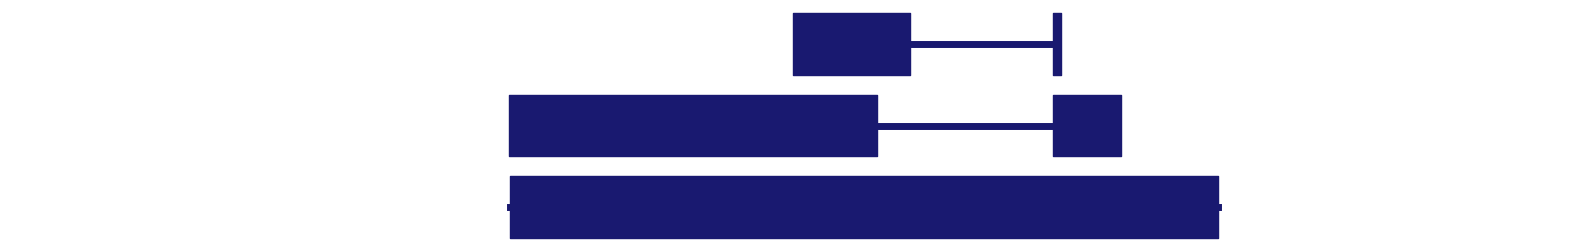

In [17]:
save(C.panel_torino_missing_junctions_CGB8_torino_iso(), 'torino_missing_junctions_CGB8_torino_iso')

## Full isoform upset (standalone)

Every isoform appears exactly once. Unlike the upsets in Figure 2, the
splicing-efficiency factors are a category rather than a filter, and so is
the leftover 'uncategorized' group -- both exclusive, so an isoform flagged
as an efficiency factor is never also counted as alt. Splicing. An
alternative first or last exon is its own category, kept separate from
alt. Splicing.

`min_subset_size` hides the tail of tiny intersections; the category totals
on the left still count every isoform.

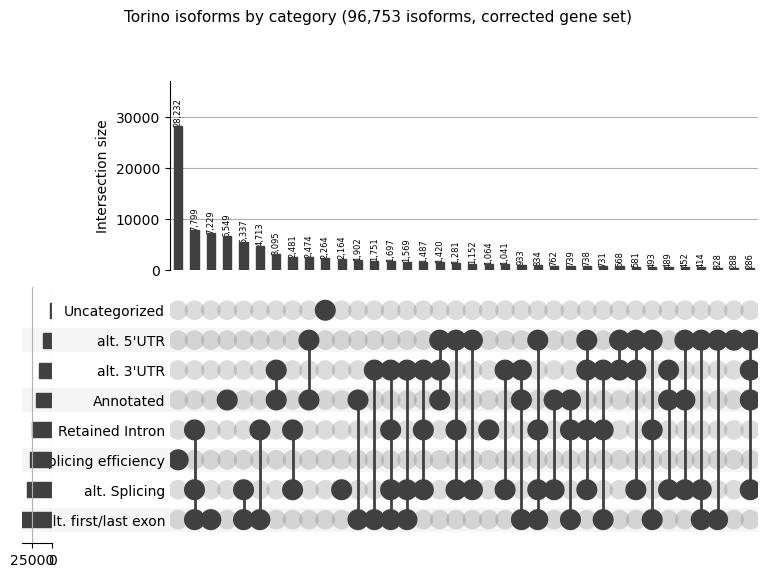

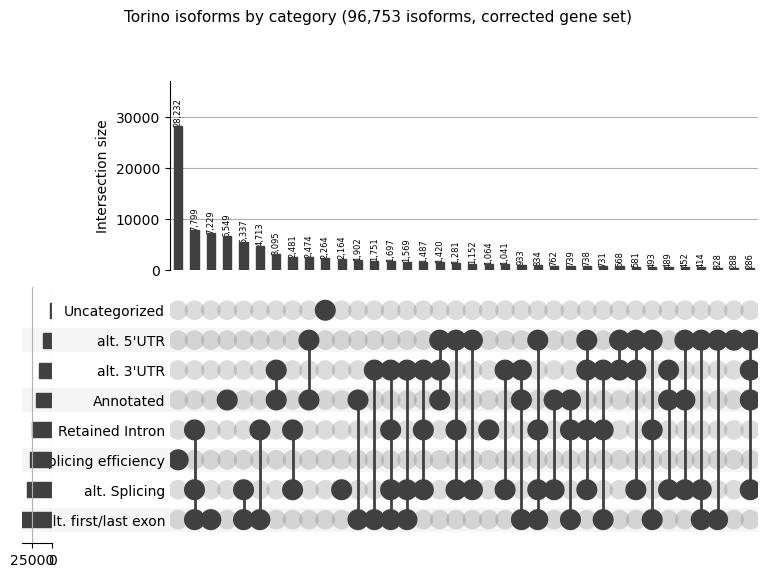

In [18]:
save(UP.panel_upset_full(), 'upset_full')

### Category sizes
Both gene sets, for the figure legend.

In [19]:
Markdown(UP.upset_table())


**Isoform categories (full upset)**

| | all genes | corrected gene set |
|---|---:|---:|
| isoforms | 98,819 | 96,753 |
| Annotated | 20,769 (21.0%) | 20,263 (20.9%) |
| Retained Intron | 24,922 (25.2%) | 24,742 (25.6%) |
| alt. Splicing | 31,352 (31.7%) | 31,249 (32.3%) |
| alt. first/last exon | 37,989 (38.4%) | 37,431 (38.7%) |
| alt. 3'UTR | 17,172 (17.4%) | 17,051 (17.6%) |
| alt. 5'UTR | 11,960 (12.1%) | 11,823 (12.2%) |
| Splicing efficiency | 28,840 (29.2%) | 28,232 (29.2%) |
| Uncategorized | 2,496 (2.5%) | 2,264 (2.3%) |
| in a single category | 49,693 (50.3%) | 47,937 (49.5%) |
| in no category | 0 (0.0%) | 0 (0.0%) |

## 3' UTR / polyadenylation numbers

Uncorrected and corrected side by side. Units are stated per row, which
matters here: a polyA **site** is a cluster of terminal-exon ends within
200 bp, while the notebook's original counts were per `gene:exon_start`,
and the two disagree. Both Torino populations are restricted to remove the
ambiguous cases -- APA to genes also labelled multi-site (71 dropped),
single-site to genes with exactly one `gene:end`.

Slow: the last two rows need the per-gene loadings loop.

In [2]:
# Markdown(U.polya_table())              # with_heatmap=False to skip the slow rows


NameError: name 'Markdown' is not defined

In [4]:
from IPython.display import Markdown

              # annotation-recovery panels
import SFigure2_utr3 as U                  # polyA panels + table

Markdown(U.polya_table(with_heatmap=False))              # with_heatmap=False to skip the slow rows


100%|██████████| 16710/16710 [02:57<00:00, 94.20it/s] 


**3' UTR / polyadenylation**

| | all genes | corrected gene set | of |
|---|---:|---:|---|
| **Genes and polyA sites** | | | |
| tested genes | 16,710 | 16,073 |  |
| genes, single site | 8,404 (50.3%) | 7,849 (48.8%) | tested genes |
| genes, two or more sites | 8,306 (49.7%) | 8,224 (51.2%) | tested genes |
| polyA sites | 30,357 | 29,619 |  |
| APA sites (sum over genes) | 21,953 | 21,770 |  |
| **Torino APA (multi-site genes, unambiguous)** | | | |
| APA genes | 4,438 | 4,433 |  |
| APA sites (gene:end) | 10,745 | 10,735 |  |
| APA sites matched by GENCODE | 6,852 (63.8%) | 6,846 (63.8%) | APA sites (gene:end) |
| APA genes dropped as ambiguous | 71 | 71 |  |
| **Torino single-site (one gene:end each)** | | | |
| single-site genes confirmed | 5,532 | 5,361 |  |
| single sites matched by GENCODE | 5,369 (97.1%) | 5,198 (97.0%) | single-site genes confirmed |
| single-site genes dropped (>1 end) | 552 | 520 |  |
| single-site genes not in the reference table | 2,320 | 1,968 |  |
| **GENCODE side (same gene:end unit)** | | | |
| GENCODE APA sites (gene:end) | 5,965 | 5,927 |  |
| GENCODE APA found by Torino | 3,513 (58.9%) | 3,496 (59.0%) | GENCODE APA sites (gene:end) |
| GENCODE constitutive sites (gene:end) | 15,266 | 14,599 |  |
| GENCODE constitutive found by Torino | 13,598 (89.1%) | 12,981 (88.9%) | GENCODE constitutive sites (gene:end) |

### polyA barplot
Source: `analysis/UTR3.ipynb` cell 65

Bars are recomputed from the table above in the `gene:end` unit, so they
follow the gene subset. `U.panel_polyA_barplot_published()` draws the
original hardcoded version, which reproduces the published PNG exactly.

In [ ]:
save(U.panel_polyA_barplot(), 'polyA_barplot')

 11%|█         | 1783/16710 [00:08<00:50, 293.55it/s]

#### The published bar heights, for comparison

Cell 65 (In[158]) verbatim: the bar heights are literals and reproduce
`supp_fig/polyA/barplot.png` pixel for pixel. Kept alongside the
recomputed version above because one of its numbers (5,959 GENCODE APA
sites) appears in no cell output and is ten short of the 5,969 the data
gives, and because its unit is `gene:exon_start` rather than `gene:end`.

In [ ]:
save(U.panel_polyA_barplot_published(), 'polyA_barplot_published')


## Cassette exons (continued)

### cassette_exons_median_loadings
Source: `analysis/CassetteExonsDeNovo.ipynb cell 94`

Mean isoform usage per annotation group. Slow: rebuilds the
cassette-with-transcripts table, which was never written to disk.

In [ ]:
save(K.panel_cassette_exons_median_loadings(), 'cassette_exons_median_loadings')

### cassette_exons_torino_v_gencode_brain_cortex
Source: `analysis/CassetteExonsDeNovo.ipynb cell 128`

In [ ]:
save(K.panel_cassette_exons_torino_v_gencode_brain_cortex(), 'cassette_exons_torino_v_gencode_brain_cortex')

## VastDB brain cassette exons

### VastDB_cassette_exons_brain
Source: `analysis/Brain_Cassette_SSMD.ipynb cell 39`

SSMD of the Torino isoform carrying each brain-specific VastDB exon
against the one skipping it. Slow: two counting loops over the PSI table.

In [ ]:
save(B.panel_VastDB_cassette_exons_brain(), 'VastDB_cassette_exons_brain')

#### Exons per curve

The n shown in each legend. Both curves in a panel are drawn over the
same rows, because `.dropna()` is applied to the frame before a column
is selected. Corrected and uncorrected agree because all 441 genes
behind the curves already fall inside the 16,073-gene set: these events
need an SSMD result, so the genes are well-expressed ones that reached
K=10 -- the same criteria the corrected set selects on.

In [ ]:
Markdown(B.vastdb_ssmd_table())


## Annotation recovery

### torino_isoform_recovery_by_length
Source: `analysis/Appris_1.ipynb cell 6`

In [ ]:
save(A.panel_torino_isoform_recovery_by_length(), 'torino_isoform_recovery_by_length')

### torino_isoform_recovery_by_expression
Source: `analysis/Appris_1.ipynb cell 66`

In [ ]:
save(A.panel_torino_isoform_recovery_by_expression(), 'torino_isoform_recovery_by_expression')

### torino_annot_transcripts
Source: `analysis/Appris_1.ipynb cell 116`

In [ ]:
save(A.panel_torino_annot_transcripts(), 'torino_annot_transcripts')

### Genes missing a GENCODE isoform, by expression

Non-overlapping genes (`whole_genes`) with no GENCODE-annotated
transcript recovered by Torino, binned by median TPM across the 18
tissues Torino tested, showing how many also lack an APPRIS principal
junction in the junction data.

Computed directly rather than replicating `Appris_1.ipynb` cells 61/67.
Those call `get_junctions_bed()` twice per transcript per gene, each
call a tabix subprocess plus a BedTool temp file -- tens of thousands of
subprocesses, which is where their ~83 min went. Here the junction table
is summarised once into `figure_data/junction_q999.pkl` and the per-gene
check is a set lookup. Thresholding is unchanged: per junction the 0.999
quantile across samples, per gene `max(q999)/200`.

The gene pool follows `GENE_SUBSET`, so these are the corrected numbers
-- they are not expected to match the published figure.

In [ ]:
save(A.panel_missing_junctions_by_expression(),
     'missing_junctions_by_expression')


In [ ]:
_tab, _tot = A.missing_junctions_numbers()
for _k, _v in _tot.items():
    print(f'{_k:<36} {_v:>9,}')
_tab


## 3' UTR heatmap

### polyA_heatmap
Source: `analysis/UTR3.ipynb cell 135`

Scaled usage of the longer 3' UTR across tissues. ~1 h: the per-gene
loadings loop, which nothing caches to disk.

In [ ]:
save(U.panel_polyA_heatmap(), 'polyA_heatmap')

### UTRs_cumulative

Long-read support for polyA sites: the cumulative share of site usage
against the share of sites, split by whether Torino and GENCODE agree.
Source: `UTR3.ipynb` cells 283 and 288 (In[1229], In[1280]).

The counts behind it come from nine ONT BAMs and live in
`figure_data/bam_counts.pkl`. If that file is missing the cell raises and
tells you to run `U.build_bam_counts()` once on a compute node; it will
not rebuild a pickle that already exists.

In [ ]:
save(U.panel_UTRs_cumulative(), 'UTRs_cumulative')


## Isoform usage by expression decile

Needs ~8 GB: `prepare_data` imputes the EL matrix. Run under
`sinteractive --mem=16G`. Which decile each panel uses is recorded in
`A.RANK_OF_PANEL` -- the notebook's execution counts collide and cannot
say, so the pairing is the one that reproduces the published PNGs.

### PCA_rank1
Source: `analysis/Appris_1.ipynb cell 41`

In [ ]:
# save(A.panel_PCA_rank1(), 'PCA_rank1')      # ~8 GB, uncomment under sinteractive


### heatmap_rank1
Source: `analysis/Appris_1.ipynb cell 43`

In [ ]:
# save(A.panel_heatmap_rank1(), 'heatmap_rank1')      # ~8 GB, uncomment under sinteractive


### PCA_rank20
Source: `analysis/Appris_1.ipynb cell 34`

In [ ]:
# save(A.panel_PCA_rank20(), 'PCA_rank20')      # ~8 GB, uncomment under sinteractive


### heatmap_rank20
Source: `analysis/Appris_1.ipynb cell 37`

In [ ]:
# save(A.panel_heatmap_rank20(), 'heatmap_rank20')      # ~8 GB, uncomment under sinteractive


## Variable APA across tissues

Where the polyA heatmap's numbers come from: the chain that produces
2,702 rows, and the brain-direction split shown by the row colours.

Source: `UTR3.ipynb` cells 125, 126, 128, 131 (In[83]-In[90]).

In [ ]:
Markdown(U.variable_apa_table())


## APA heatmaps

Three further heatmaps over the APA sites, alongside `polyA_heatmap`
above. All three plot relative 3' UTR usage per tissue, row-scaled,
with rows coloured by whether usage is higher in brain; they differ
in which population and which pair of ends they use.

| panel | population | ends compared |
|---|---|---|
| `polyA_heatmap_apa_sites` | genes behind the APA sites, strict subset | longest vs shortest |
| `polyA_heatmap_apa_extremes` | APA loci, terminal-exon groups recomputed | longest vs shortest |
| `polyA_heatmap_apa` | the same recomputed loci | the two most-used |


### Longest vs shortest APA site, per gene

Every end plotted is one of the APA sites; the table below
verifies that, shows how the gene set narrows, and gives the
brain split at four cutoffs.

In [ ]:
save(U.panel_polyA_heatmap_apa_sites(), 'polyA_heatmap_apa_sites')


In [ ]:
Markdown(U.apa_site_table())


### The same loci, the two most-used ends

Recomputed terminal-exon groups rather than the site table, so
the loci are not a strict subset. Included because the contrast
with the panel above isolates the effect of the pair choice:
comparing the dominant pair instead of the extremes drops the
brain fraction from ~85% to ~63%.

In [ ]:
save(U.panel_polyA_heatmap_apa(), 'polyA_heatmap_apa')


In [ ]:
save(U.panel_polyA_heatmap_apa_extremes(), 'polyA_heatmap_apa_extremes')
